In [42]:
import warnings
warnings.filterwarnings('ignore')

In [43]:
import matplotlib.pyplot as plt
import math
import json
import numpy as np
import torch
import pickle
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr
from mpl_toolkits.mplot3d import Axes3D

In [44]:
start = -np.pi/2
end = np.pi/2
n = 300
batch_size = 16
modelSamples = 50

In [45]:
# Define the Ishigami function
def ishigami_function(x1, x2, x3, a=7, b=0.1):
    return np.sin(x1) + a * np.sin(x2)**2 + b * x3**4 * np.sin(x1)

# Generate Ishigami dataset with added variance
def generate_ishigami_dataset(start, end, n_samples):
    np.random.seed(0)
    x1 = np.random.uniform(start, end, n_samples)
    x2 = np.random.uniform(start, end, n_samples)
    x3 = np.random.uniform(start, end, n_samples)
    f_x = ishigami_function(x1, x2, x3)
    # Add variance to y
    y_var = 0.2
    y = np.random.normal(f_x, y_var, n_samples)
    return x1, x2, x3, y

In [46]:
x1, x2, x3, y = generate_ishigami_dataset(start, end, n)

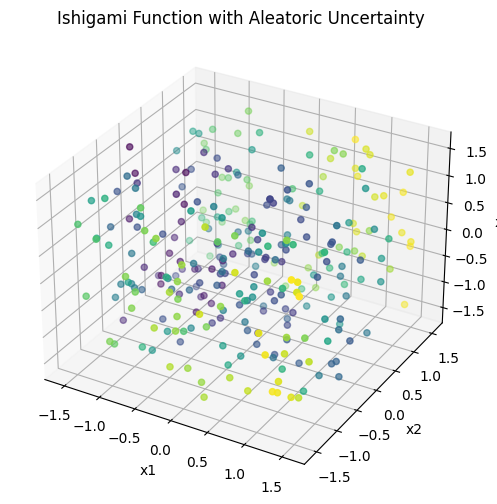

In [47]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, x3, c=y, cmap='viridis')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Ishigami Function with Aleatoric Uncertainty')
plt.show()


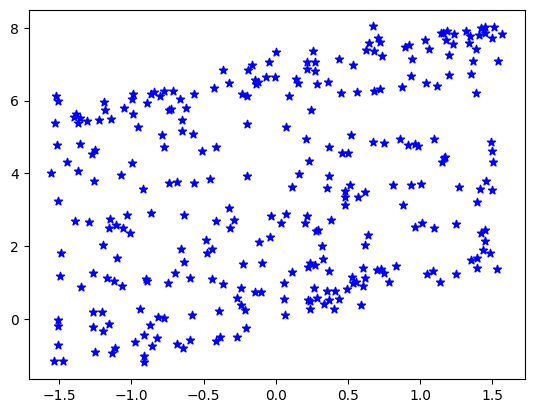

In [48]:

x1_train, y_train = x1,y
scatter(x1_train, y_train, c="blue", marker="*")


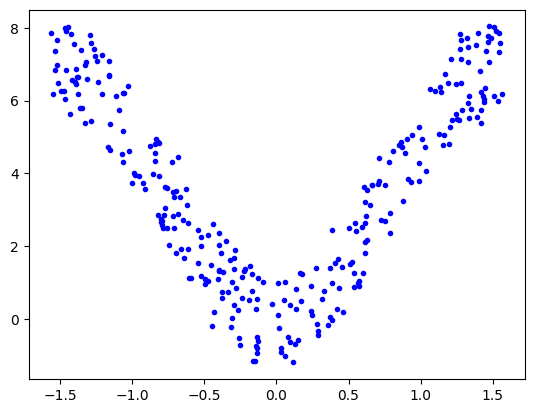

In [49]:
x2_train, y_train = x2,y
scatter(x2_train, y_train, c="blue", marker=".")

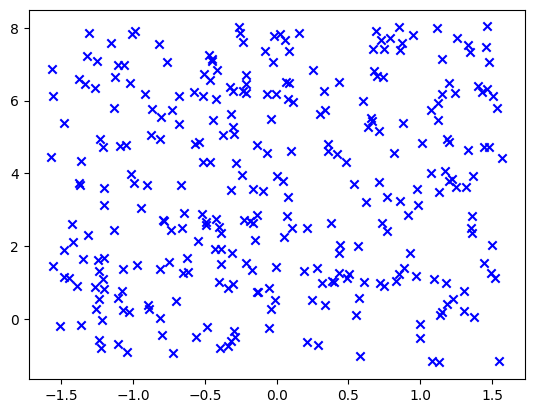

In [50]:
x3_train, y_train = x3,y
scatter(x3_train, y_train, c="blue", marker="x")

In [51]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x1_test, x2_test,x3_test, y_test = generate_ishigami_dataset(-np.pi, np.pi, 200)


<Figure size 400x400 with 0 Axes>

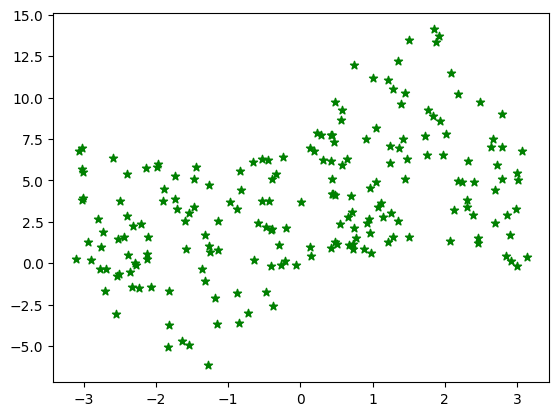

In [52]:
scatter(x1_test, y_test, c="green", marker="*")

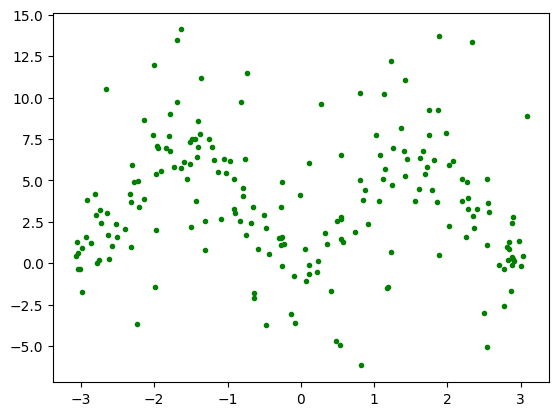

In [53]:
scatter(x2_test, y_test, c="green", marker=".")

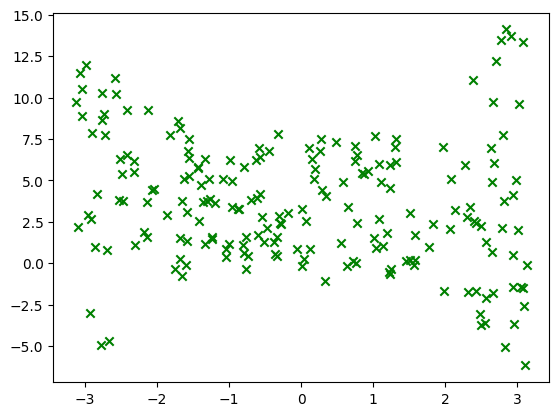

In [54]:
scatter(x3_test, y_test, c="green", marker="x")

In [55]:
# #Plotting In Training Distribution Data Points in the Test Set
# # Filter the data to retain only the desired ranges
# mask_x1_test_idd =  (x1_test >= start) &  (x1_test <= end) # Select the ranges -pi/2 to pi/2
# x1_test_idd = x1_test[mask_x1_test_idd]
# y_test_idd = y_test[mask_x1_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x1_test_idd, y_test_idd, c="yellow", marker="*")

# plt.show()


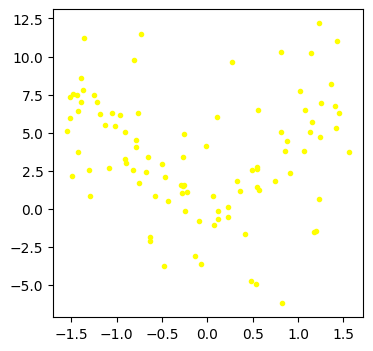

In [56]:
mask_x2_test_idd =  (x2_test >= start) &  (x2_test <= end) # Select the ranges -pi/2 to pi/2
x2_test_idd = x2_test[mask_x2_test_idd]
y_test_idd = y_test[mask_x2_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x2_test_idd, y_test_idd, c="yellow", marker=".")

plt.show()

In [57]:
# mask_x3_test_idd =  (x3_test >= start) &  (x3_test <= end) # Select the ranges -pi/2 to pi/2
# x3_test_idd = x3_test[mask_x3_test_idd]
# y_test_idd = y_test[mask_x3_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x3_test_idd, y_test_idd, c="yellow", marker="x")

# plt.show()

In [58]:
# #Plotting Out of Training Distribution Data Points in the Test Set
# # Filter the data to retain only the desired ranges
# mask_x1_test_oodd = (x1_test >= -np.pi) & (x1_test < start) | (x1_test > end) & (x1_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x1_test_oodd = x1_test[mask_x1_test_oodd]
# y_test_oodd = y_test[mask_x1_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x1_test_oodd, y_test_oodd, c="red", marker="*")

# plt.show()


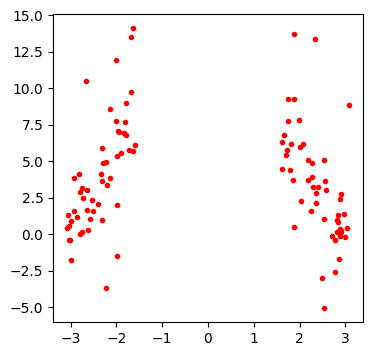

In [59]:
mask_x2_test_oodd = (x2_test >= -np.pi) & (x2_test < start) | (x2_test > end) & (x2_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x2_test_oodd = x2_test[mask_x2_test_oodd]
y_test_oodd = y_test[mask_x2_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x2_test_oodd, y_test_oodd, c="red", marker=".")

plt.show()

In [60]:
# mask_x3_test_oodd = (x3_test >= -np.pi) & (x3_test < start) | (x3_test > end) & (x3_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x3_test_oodd = x3_test[mask_x3_test_oodd]
# y_test_oodd = y_test[mask_x3_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x3_test_oodd, y_test_oodd, c="red", marker="x")

# plt.show()

In [61]:

# Train
tensor_x = torch.Tensor(x2_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x2_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

# #Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x2_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x2_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [62]:
print(f"tensor_x_test_oodd.shape: {tensor_x_test_oodd.shape}")
print(f"tensor_y_test_oodd.shape: {tensor_y_test_oodd.shape}")

tensor_x_test_oodd.shape: torch.Size([103, 1])
tensor_y_test_oodd.shape: torch.Size([103, 1])


In [63]:
class DeepONet(nn.Module):
    def __init__(self):
        super(DeepONet, self).__init__()
        self.hidden_size = 35

        # We only have 1 input feature
        self.b1 = nn.Linear(1, self.hidden_size)
        self.b2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.t1 = nn.Linear(self.hidden_size, self.hidden_size)
        self.t2 = nn.Linear(self.hidden_size, self.hidden_size)

        self.mu = nn.Linear(self.hidden_size, 1)
        self.var = nn.Linear(self.hidden_size, 1)

    def forward(self, x):

        h = torch.tanh(self.b1(x))
        h = torch.tanh(self.b2(h))

        input_noise = torch.normal(0, 1, size=(x.shape[0], self.hidden_size))

        t           = torch.tanh(self.t1(input_noise))
        t           = torch.tanh(self.t2(t))
        prod        = torch.multiply(t,h)

        mu = self.mu(prod)
        # Exponential activation to enforce positive var

        var = torch.exp(self.var(prod))
        return mu, var


In [64]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    # Get predictions
    mus = []
    vars = []

    for m in range(modelSamples):
        mu, var = model(tensor_x_test)
        mus.append(mu)
        vars.append(var)
    # For epistemic uncertainty we calculate the std on the mus!

    means = torch.stack(mus).mean(axis=0).detach().numpy()

    # stds = torch.stack(vars).mean(axis=0).detach().numpy()**(1/2)
    stds = torch.stack(mus).std(axis=0).detach().numpy()**(1/2) + \
                torch.stack(vars).mean(axis=0).detach().numpy()**(1/2)

    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=0.5)
    plt.show()
    return percentage_count_within_ci


In [65]:


def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test,y_test,color,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.GaussianNLLLoss(eps=1e-02)
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            mu, var = net(x)
            loss = criterion(mu, y, var)
            loss.backward()
            optimizer.step()
            criterionmse_train = nn.MSELoss()
            mse_train = criterionmse_train(mu, y)
        if epoch % 10 == 0:
            all_test_losses = []
            all_mse_test = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                mu, var = net(x)
                all_test_losses.append(criterion(mu, y, var).item())
                criterionmse_test = nn.MSELoss()
                all_mse_test.append(criterionmse_test(mu, y).item())
            test_loss = sum(all_test_losses) / len(all_test_losses)
            test_mse = sum(all_mse_test) / len(all_mse_test)
    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color):
    loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color)
    return loss, test_loss, mse_train, test_mse,net,percentage_count_within_ci



In [66]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x2_test,
    "x_test_oodd": x2_test_oodd,
    "x_test_idd": x2_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}

# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 45.0


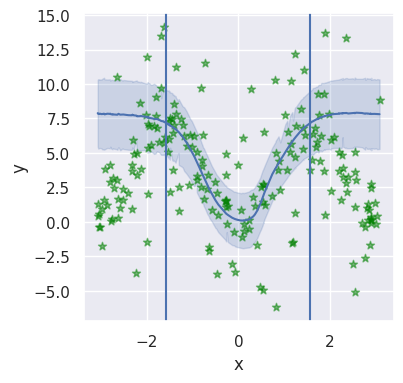

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 44.5


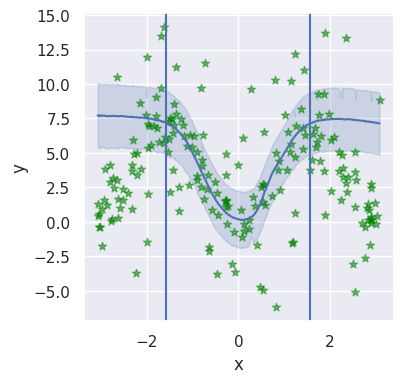

Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 45.0


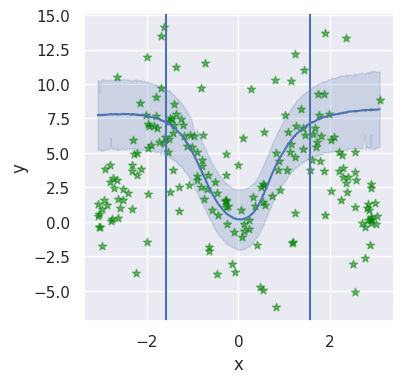

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 44.5


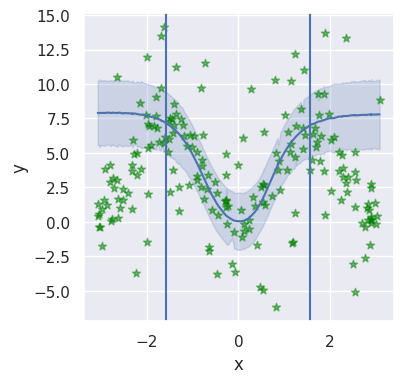

Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 45.0


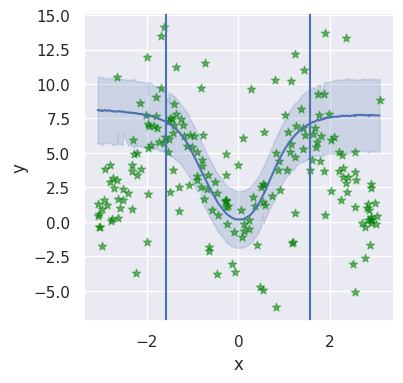

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 44.5


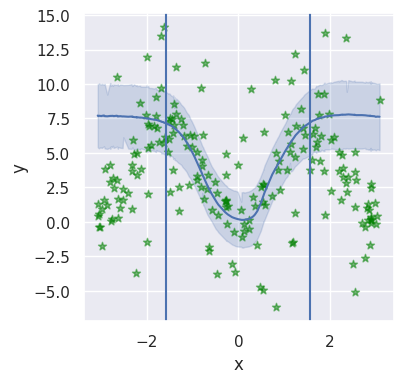

Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 45.0


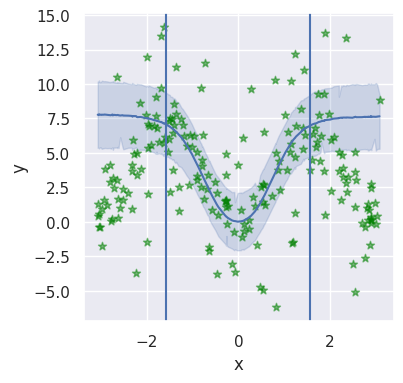

Number of data points within the 95% confidence interval: 90
Percentage of data points within the 95% confidence interval: 45.0


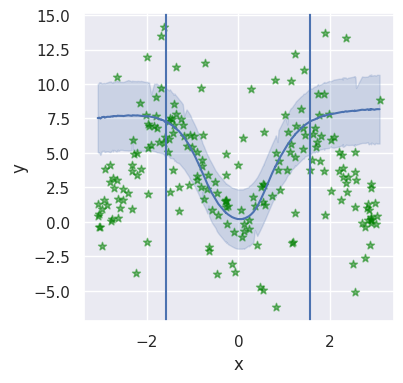

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 44.5


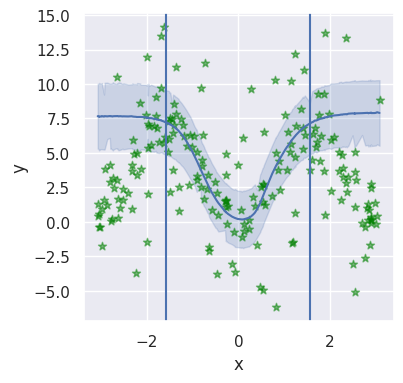

Number of data points within the 95% confidence interval: 89
Percentage of data points within the 95% confidence interval: 44.5


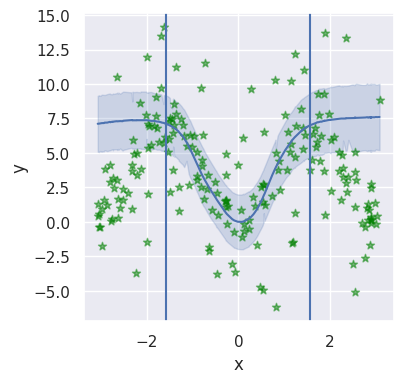

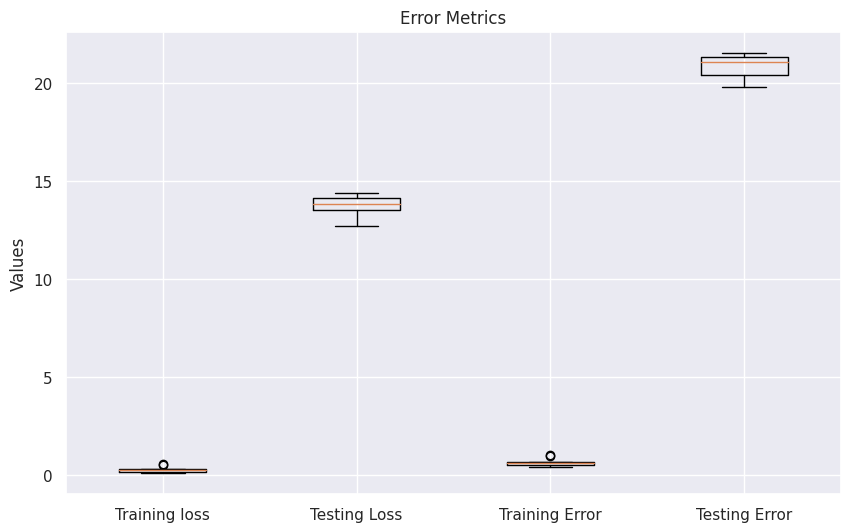

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        0.305200     13.912806                     0.669450   
2        0.310054     14.163553                     0.691788   
3        0.149646     13.190728                     0.457885   
4        0.539792     13.452912                     0.989489   
5        0.259341     12.704769                     0.629430   
6        0.561696     14.036090                     1.018592   
7        0.266142     14.291027                     0.624396   
8        0.289116     14.402612                     0.670202   
9        0.140252     13.756460                     0.457999   
10       0.123425     13.817690                     0.441716   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    21.417249                                45.0  
2                    20.279753                                44.5  
3                    21.565304                                45.0  
4                  

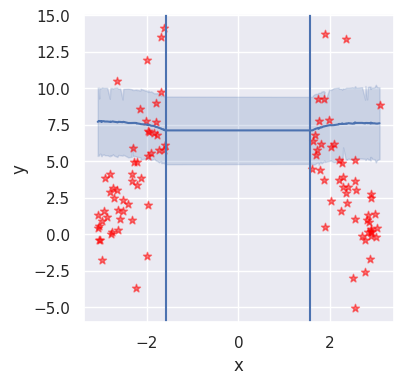

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


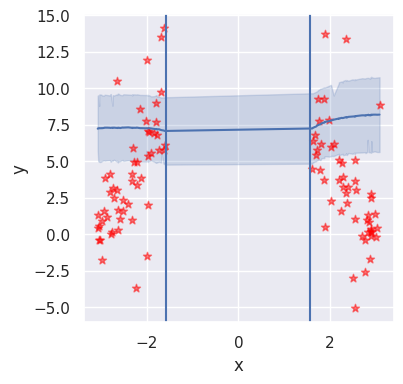

Number of data points within the 95% confidence interval: 30
Percentage of data points within the 95% confidence interval: 29.126213592233007


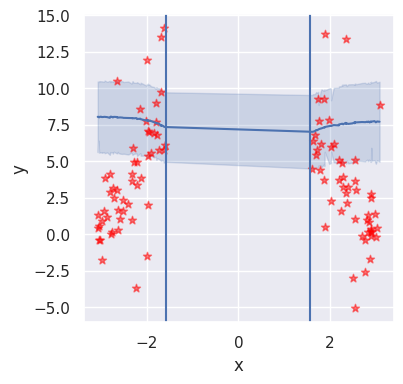

Number of data points within the 95% confidence interval: 29
Percentage of data points within the 95% confidence interval: 28.155339805825243


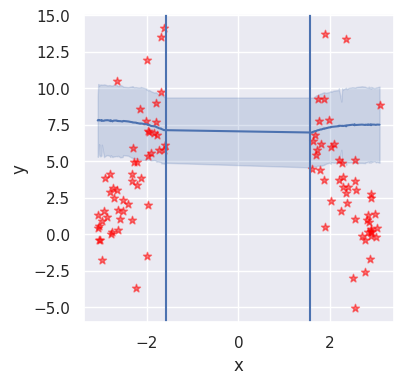

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


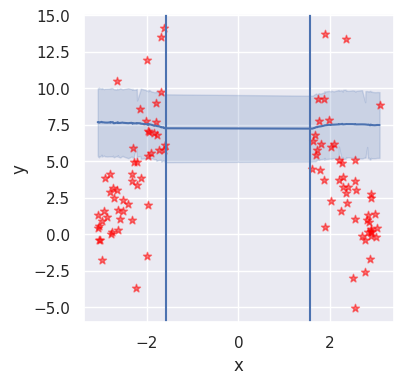

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


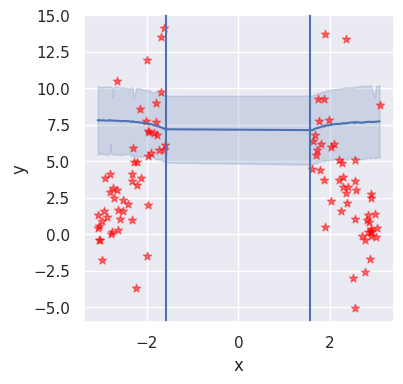

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


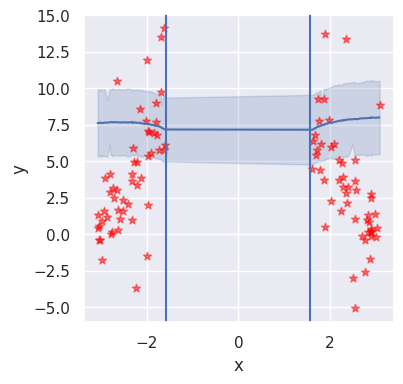

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


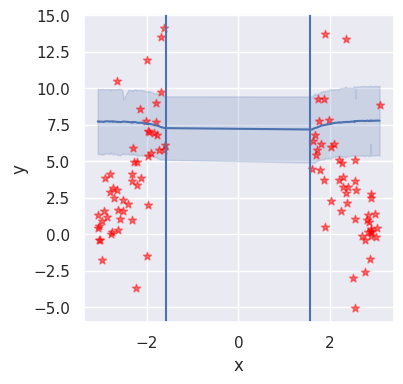

Number of data points within the 95% confidence interval: 28
Percentage of data points within the 95% confidence interval: 27.184466019417474


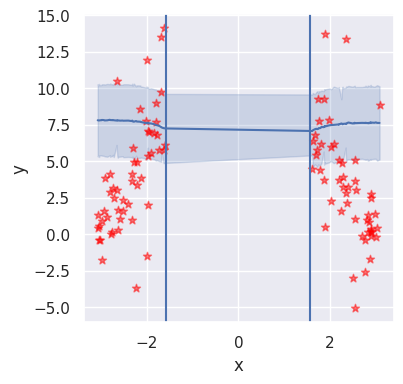

Number of data points within the 95% confidence interval: 26
Percentage of data points within the 95% confidence interval: 25.24271844660194


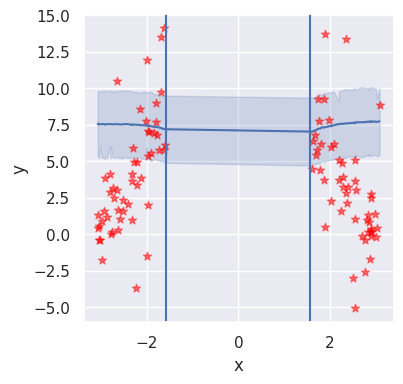

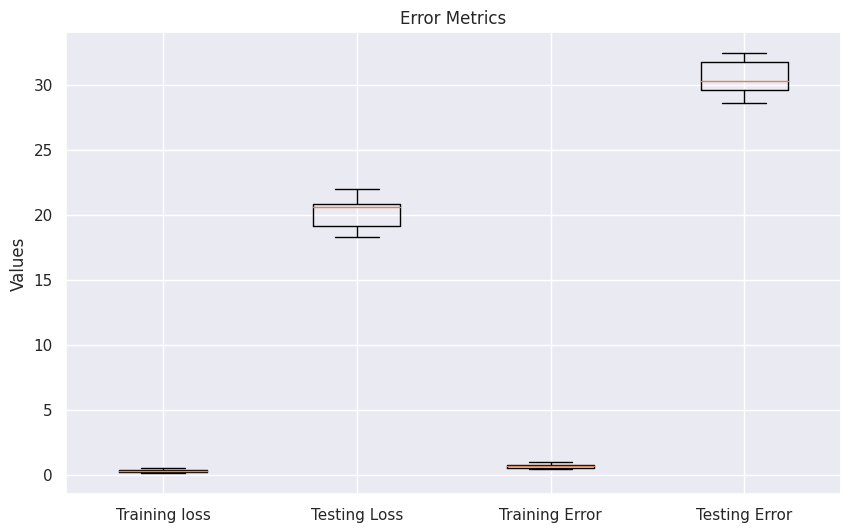

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        0.316821     20.875955                     0.696849   
2        0.363854     18.985185                     0.749744   
3        0.188907     19.594161                     0.525246   
4        0.477646     18.997652                     0.883512   
5        0.332421     20.582882                     0.722657   
6        0.150033     21.958487                     0.457492   
7        0.163860     18.314642                     0.475757   
8        0.373488     20.855973                     0.771687   
9        0.554956     20.518169                     1.017631   
10       0.289861     20.714293                     0.646482   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                    29.773958                           25.242718  
2                    30.293688                           25.242718  
3                    32.436481                           29.126214  
4                  

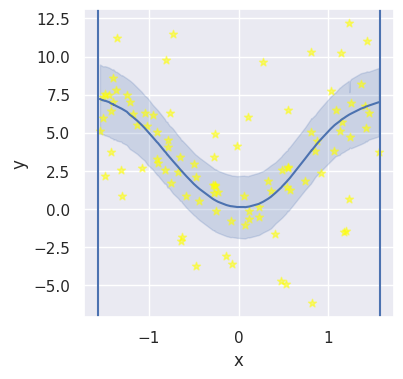

Number of data points within the 95% confidence interval: 64
Percentage of data points within the 95% confidence interval: 65.97938144329896


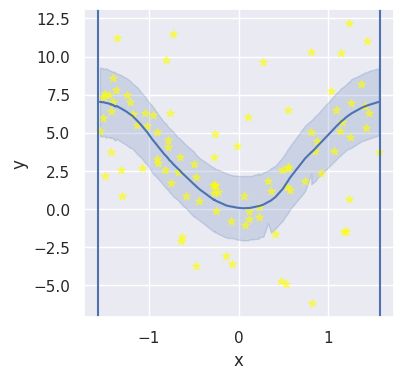

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


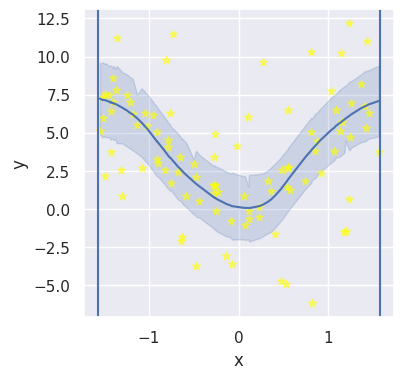

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


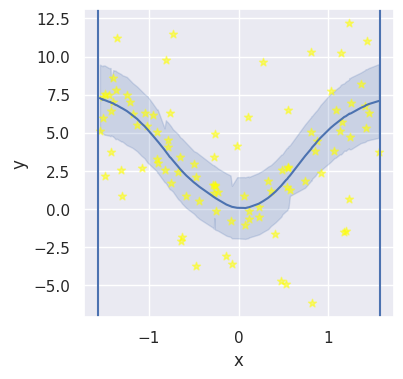

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


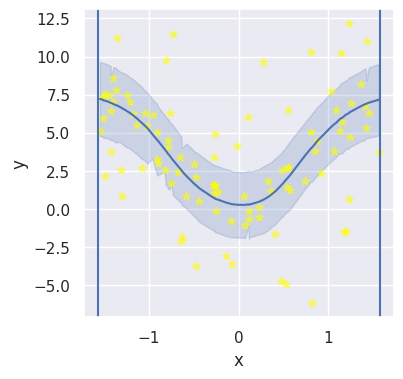

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


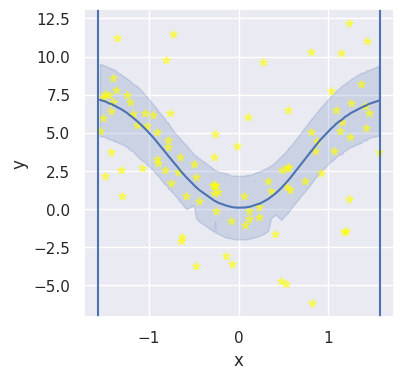

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


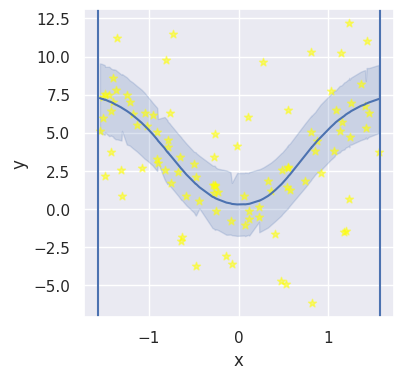

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


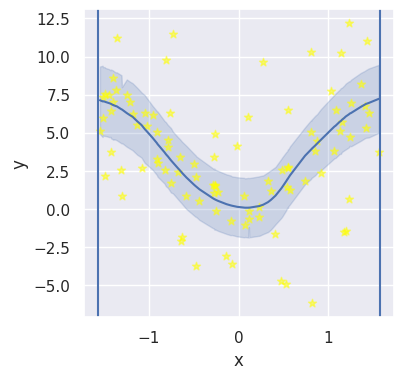

Number of data points within the 95% confidence interval: 63
Percentage of data points within the 95% confidence interval: 64.94845360824742


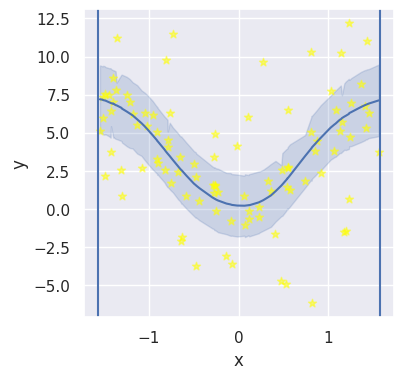

Number of data points within the 95% confidence interval: 64
Percentage of data points within the 95% confidence interval: 65.97938144329896


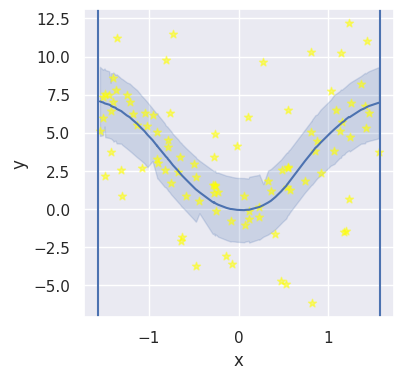

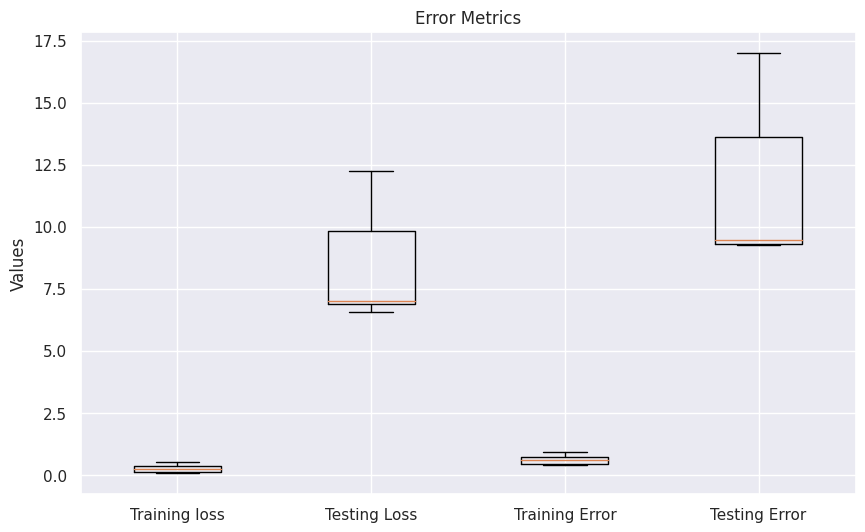

    Training Loss  Testing Loss  Mean Squared Training Error  \
1        0.163346      6.550194                     0.489361   
2        0.355738      7.037975                     0.744119   
3        0.360785      6.870660                     0.763725   
4        0.184602      6.871197                     0.519690   
5        0.342803      9.032538                     0.733977   
6        0.113539     12.240075                     0.418587   
7        0.091359      6.867018                     0.386799   
8        0.115571      6.960970                     0.421304   
9        0.330346     10.071214                     0.727398   
10       0.507403     11.522400                     0.910302   

    Mean Squared Testing Error  % of points in Confidence Interval  
1                     9.287108                           64.948454  
2                     9.396455                           65.979381  
3                     9.520334                           64.948454  
4                  

In [67]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets):
  train_losses=[]
  test_losses=[]
  errors_train=[]
  errors_test=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=DeepONet()
    tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col)
    error_metrics=tr_loss,test_loss,mse_tr,mse_test,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)
    errors_train.append(mse_tr)
    errors_test.append(mse_test)
    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses
  tr_errors_values= [tensor.item() for tensor in errors_train]
  test_errors_values= errors_test
  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values, tr_errors_values, test_errors_values]
  box_labels = ['Training loss', 'Testing Loss', 'Training Error', 'Testing Error']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'donn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_mse_train = np.mean(tr_errors_values)
  std_dev_mse_train = np.std(tr_errors_values)

  mean_mse_test = np.mean(test_errors_values)
  std_dev_mse_test = np.std(test_errors_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    'Mean Squared Training Error': tr_errors_values,
    'Mean Squared Testing Error': test_errors_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss', 'Mean Squared Training Error','Mean Squared Testing Error','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'donn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of MSE Training of 10 runs ',mean_mse_train)
  print('Standard Deviation of MSE Training of 10 runs ' , std_dev_mse_train)

  print('Mean of MSE Testing of 10 runs ',mean_mse_test )
  print('Standard Deviation of MSE Testing of 10 runs ', std_dev_mse_test)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'donn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of MSE Training of 10 runs: {}\n'.format(mean_mse_train))
    file.write('Standard Deviation of MSE Training of 10 runs: {}\n\n'.format(std_dev_mse_train))

    file.write('Mean of MSE Testing of 10 runs: {}\n'.format(mean_mse_test))
    file.write('Standard Deviation of MSE Testing of 10 runs: {}\n\n'.format(std_dev_mse_test))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
